# Project Visualizations

In [1]:
#Import necessary packages
import numpy as np
import pandas as pd
import seaborn as sns
import sqlite3

## Load NYPD Arrests Data

In [2]:
nypd_2021 = pd.read_csv("NYPD_Arrest_Data__Year_to_Date_.csv")
nypd_2006_2020 = pd.read_csv("NYPD_Arrests_Data__Historic_.csv")
#nypd_2021.to_sql(table_name, conn, if_exists='append', index=False)

nypd_arrests = pd.concat([nypd_2006_2020, nypd_2021], ignore_index=True)
nypd_arrests.head()

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,JURISDICTION_CODE,AGE_GROUP,PERP_SEX,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lon_Lat,New Georeferenced Column
0,32311380,06/18/2007,511.0,"CONTROLLED SUBSTANCE, POSSESSION 7",235.0,DANGEROUS DRUGS,PL 2200300,M,Q,27,1.0,18-24,M,BLACK,NaN,NaN,NaN,NaN,NaN,NaN
1,192799737,01/26/2019,177.0,SEXUAL ABUSE,116.0,SEX CRIMES,PL 1306503,F,M,25,0.0,45-64,M,BLACK,1000555.0,230994.0,40.800694,-73.941109,POINT (-73.94110928599997 40.800694331000045),NaN
2,193260691,02/06/2019,NaN,NaN,NaN,NaN,PL 2203400,F,M,14,0.0,25-44,M,UNKNOWN,986685.0,215375.0,40.757839,-73.991212,POINT (-73.99121211099998 40.75783900300007),NaN
3,149117452,01/06/2016,153.0,RAPE 3,104.0,RAPE,PL 1302503,F,K,67,0.0,25-44,M,BLACK,998032.0,175598.0,40.648650,-73.950336,POINT (-73.95033556299995 40.648650085000035),NaN
4,190049060,11/15/2018,157.0,RAPE 1,104.0,RAPE,PL 1303501,F,K,77,0.0,25-44,M,BLACK,1003606.0,185050.0,40.674583,-73.930222,POINT (-73.93022154099998 40.67458330800008),NaN


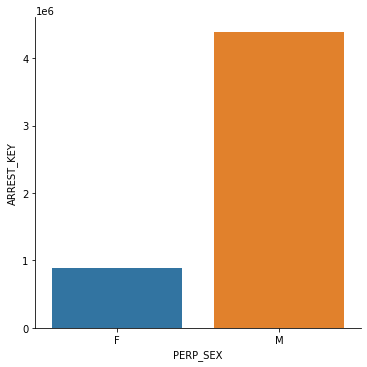

In [3]:
arrests_gender = nypd_arrests.groupby("PERP_SEX").count()
arrests_gender.head()
sns.catplot(x=arrests_gender.index, y="ARREST_KEY", kind="bar", data=arrests_gender)

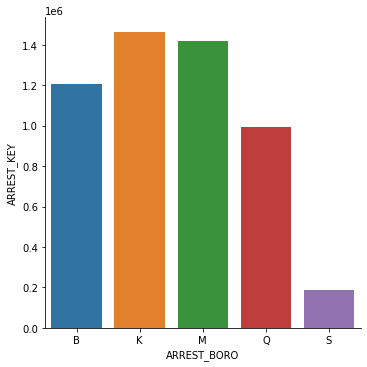

In [4]:
arrests_borough = nypd_arrests.groupby("ARREST_BORO").count()
arrests_borough.head()
sns.catplot(x=arrests_borough.index, y="ARREST_KEY", kind="bar", data=arrests_borough)

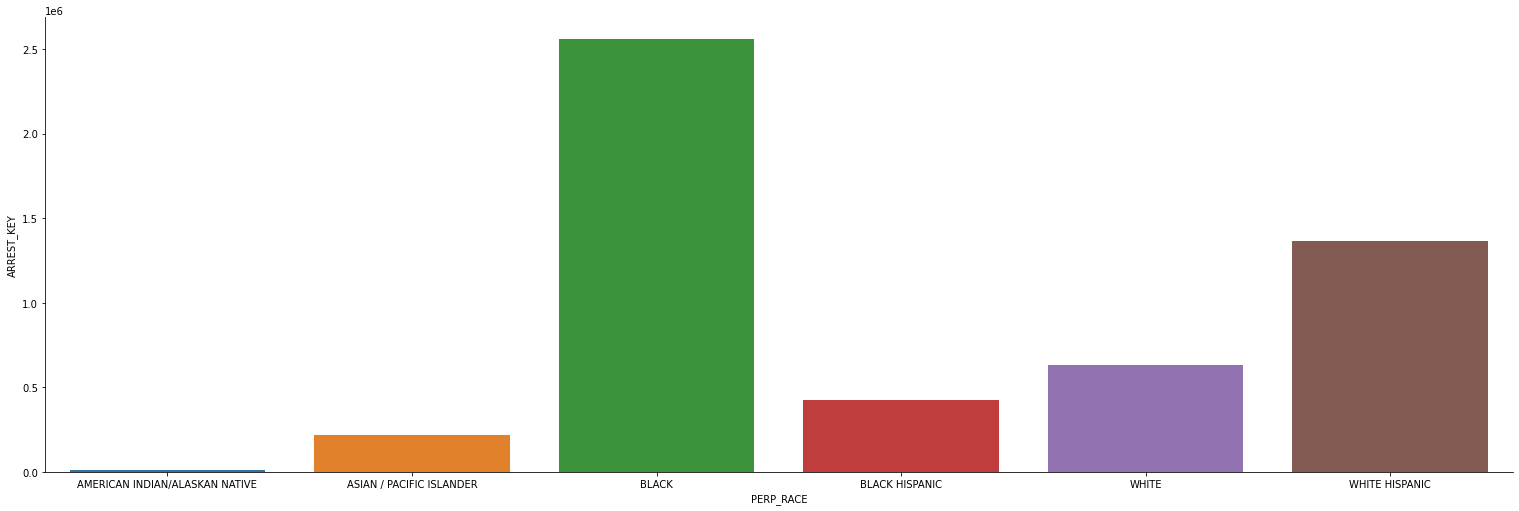

In [5]:
nypd_arrests = nypd_arrests[(nypd_arrests["PERP_RACE"] != "OTHER") & (nypd_arrests["PERP_RACE"] != "UNKNOWN")]
arrests_race = nypd_arrests.groupby("PERP_RACE").count()
arrests_race.head()
sns.catplot(x=arrests_race.index, y="ARREST_KEY", kind="bar", height=7, aspect=3, data=arrests_race)

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,JURISDICTION_CODE,AGE_GROUP,PERP_SEX,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lon_Lat,New Georeferenced Column
YEAR,,,,,,,,,,,,,,,,,,,,
2006,367178,367178,367116,367104,367104,367104,367116,366060,367178,367178,367170,367161,367178,367178,367178,367178,367178,367178,367178,0
2007,399179,399179,399142,399128,399128,399128,399142,398096,399179,399179,399177,399179,399179,399179,399178,399178,399178,399178,399178,0
2008,397913,397913,397891,397759,397759,397759,397891,396800,397909,397913,397913,397913,397913,397913,397913,397913,397913,397913,397913,0
2009,417464,417464,417455,417208,417208,417208,417455,416221,417461,417464,417464,417464,417464,417464,417464,417464,417464,417464,417464,0
2010,417916,417916,417909,417276,417276,417276,417909,416790,417916,417916,417916,417916,417916,417916,417916,417916,417916,417916,417916,0


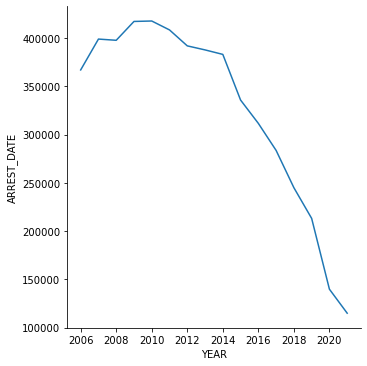

In [6]:
#print(nypd_arrests.dtypes)
nypd_arrests["ARREST_DATE"] = pd.to_datetime(nypd_arrests["ARREST_DATE"])
nypd_arrests['YEAR'] = pd.DatetimeIndex(nypd_arrests["ARREST_DATE"]).year
arrests_year = nypd_arrests.groupby('YEAR').count()
sns.relplot(data=arrests_year, x=arrests_year.index, y="ARREST_DATE", kind="line")
arrests_year.head()

There appears to be a negative relationship between year ans number of arrests made such that there are fewer arrests made over the years

In [7]:
# Create linear regression to model number of arrests as a function of year
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

data = arrests_year.index.values.reshape(-1, 1)
target = arrests_year["ARREST_DATE"].values
linear_model = LinearRegression()
linear_model.fit(X=data, y=target)

arrests_year["PREDICTED_ARRESTS"] = linear_model.predict(data)

mse = mean_squared_error(arrests_year["ARREST_DATE"].values, arrests_year["PREDICTED_ARRESTS"].values) # float: MSE
r2 = r2_score(arrests_year["ARREST_DATE"].values, arrests_year["PREDICTED_ARRESTS"].values) # float: R^2 score
print("MSE:", mse, "r^2:", r2)


MSE: 2253641284.7188783 r^2: 0.75635759386108


   BoroCode       BoroName     Shape_Leng    Shape_Area  \
0         5  Staten Island  330470.010332  1.623820e+09   
1         4         Queens  896344.047763  3.045213e+09   
2         3       Brooklyn  741080.523166  1.937479e+09   
3         2          Bronx  464392.991824  1.186925e+09   
4         1      Manhattan  359299.096471  6.364715e+08   

                                            geometry ARREST_BORO  ARREST_KEY  \
0  MULTIPOLYGON (((-8243264.851 4948597.836, -824...           S      185669   
1  MULTIPOLYGON (((-8219461.925 4952778.732, -821...           Q      981608   
2  MULTIPOLYGON (((-8222843.672 4950893.793, -822...           B     1191506   
3  MULTIPOLYGON (((-8226155.130 4982269.949, -822...           B     1191506   
4  MULTIPOLYGON (((-8238858.864 4965915.024, -823...           M     1403874   

   longitude  latitude  
0   -8260264   4948597  
1   -8229461   4972778  
2   -8236843   4960893  
3   -8229155   4994269  
4   -8238858   4978915  


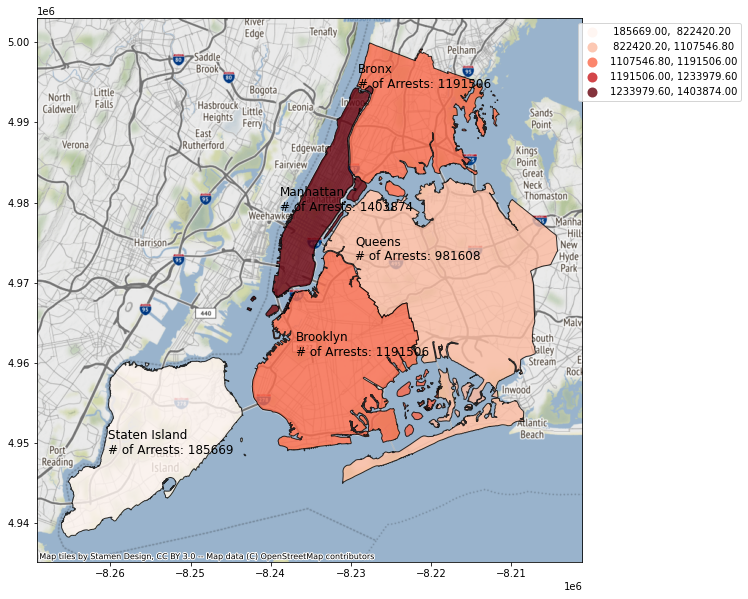

In [32]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt
import contextily as cx
import mapclassify
#Map of Number of Crimes by Borough from 2006-2021
ny_boro = gpd.read_file(gpd.datasets.get_path('nybb'))
ny_boro['ARREST_BORO'] = ny_boro["BoroName"].str.slice(stop=1)
arrest_groups = nypd_arrests.groupby(['ARREST_BORO']).count()
boro_arrests = ny_boro.merge(arrest_groups, on='ARREST_BORO')
boro_arrests = boro_arrests[["BoroCode", "BoroName", "Shape_Leng", "Shape_Area", "geometry", "ARREST_BORO", "ARREST_KEY"]]
boro_arrests['longitude']=[-8260264,-8229461,-8236843,-8229155,-8238858]
boro_arrests['latitude']=[4948597,4972778,4960893,4994269,4978915]
ny_boro_wm = boro_arrests.to_crs(epsg=3857)
print(ny_boro_wm)
ny_map = ny_boro_wm.plot(column='ARREST_KEY',figsize=(10, 10),alpha=0.8, edgecolor='k',cmap='Reds',legend=True,scheme="quantiles")
cx.add_basemap(ny_map)
# add boroughs' names with number of arrests
for i in range(len(ny_boro_wm)):
    plt.text(ny_boro_wm.longitude[i],ny_boro_wm.latitude[i],"{}\n# of Arrests: {}".format(ny_boro_wm.BoroName[i],ny_boro_wm.ARREST_KEY[i]), size = 12)    
leg = ny_map.get_legend()
leg.set_bbox_to_anchor((1.3,1))
plt.show()

In [9]:
#print(boro_arrests)
#nypd_arrests.pivot_table('LAW_CAT_CD', ['PERP_SEX', 'AGE_GROUP', 'PERP_RACE'], 'ARREST_BORO')
#ny_map = ny_boro.plot(figsize=(10, 10), alpha=0.5, edgecolor='k')

In [10]:
#Top 10 arrest precincts
#Level of offense: felony, misdemeanor, violation
#Arrest Borough
#Age group
#Jurisdiction code: Jurisdiction responsible for arrest. 
#Jurisdiction codes 0(Patrol), 1(Transit) and 2(Housing) represent NYPD 
#whilst codes 3 and more represent non NYPD jurisdictions
# I think it could be interesting to build a model 
#to predict if a person is arrested or not using the other variables in your dataset such as sex or race. 
#create a linear model that predicts the number of crimes given the date

#Create logistic model that predicts level of offense by age group, race, sex, and arr